# Finding 3 - home advantage in the 2020/21 season (Lu)

In my EDA the 2020/21 season (played without fans) was the only one where away teams won more than home teams. Here I check if that gap is bigger than what we would get by chance, and if it is outside the normal ups and downs between seasons.

Data is the same as in `eda.ipynb`: Nate's `epl_data.csv` for 2016/17-2023/24, Youssef's `football_matches_2024_2025.csv` for 2024/25 and `E0.csv` for 2025/26.

In [1]:
import polars as pl
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
%matplotlib inline

## Season table

Same code as `eda.ipynb`. I keep the counts this time (not only %) because the test needs them. 2024 in Nate's file is only half a season so it's replaced by Youssef's data.

In [2]:
def count_results(df, season, source):
    return df.select(
        season=pl.lit(season),
        matches=pl.len(),
        home_wins=(pl.col("FTR") == "H").sum(),
        draws=(pl.col("FTR") == "D").sum(),
        away_wins=(pl.col("FTR") == "A").sum(),
        source=pl.lit(source),
    )

history = pl.read_csv("data/epl_data.csv")

nate = (history.filter(pl.col("season").is_between(2016, 2023))
    .group_by("season")
    .agg(matches=(pl.col("matches_played").sum() / 2).cast(pl.Int64),
         home_wins=pl.col("home_matches_win").sum(),
         draws=pl.col("home_matches_draw").sum(),
         away_wins=pl.col("away_matches_win").sum())
    .with_columns(source=pl.lit("epl_data.csv")))

youssef = (pl.read_csv("data/football_matches_2024_2025.csv")
    .filter(pl.col("competition_name") == "Premier League")
    .with_columns(FTR=pl.col("match_outcome").replace({"Home Win": "H", "Draw": "D", "Away Win": "A"})))

seasons = (pl.concat([nate,
                      count_results(youssef, 2024, "football_matches_2024_2025.csv"),
                      count_results(pl.read_csv("data/E0.csv"), 2025, "E0.csv")],
                     how="vertical_relaxed")
    .with_columns(
        label=pl.col("season").cast(pl.String) + "/" + ((pl.col("season") + 1) % 100).cast(pl.String).str.zfill(2),
        home_win_pct=100 * pl.col("home_wins") / pl.col("matches"),
        away_win_pct=100 * pl.col("away_wins") / pl.col("matches"))
    .with_columns(gap=pl.col("home_win_pct") - pl.col("away_win_pct"))
    .sort("season"))

seasons.select("label", "matches", "home_wins", "draws", "away_wins",
               pl.col("home_win_pct", "away_win_pct", "gap").round(1))

label,matches,home_wins,draws,away_wins,home_win_pct,away_win_pct,gap
str,i64,i64,i64,i64,f64,f64,f64
"""2016/17""",380,187,84,109,49.2,28.7,20.5
"""2017/18""",380,173,99,108,45.5,28.4,17.1
"""2018/19""",380,181,71,128,47.6,33.7,13.9
"""2019/20""",380,172,92,116,45.3,30.5,14.7
"""2020/21""",380,144,83,153,37.9,40.3,-2.4
"""2021/22""",380,163,88,129,42.9,33.9,8.9
"""2022/23""",380,184,87,109,48.4,28.7,19.7
"""2023/24""",380,175,82,123,46.1,32.4,13.7
"""2024/25""",380,155,93,132,40.8,34.7,6.1


## Main test: 2020/21 vs the other nine seasons

I put the nine seasons with fans together as the baseline. Comparing 2020/21 with just one other season isn't great because one season already moves around a lot (see the check at the end).

95% CIs use the Wilson method, and the test is a two-proportion z-test (H0: same home win rate).

In [3]:
covid = seasons.filter(pl.col("season") == 2020)
rest = seasons.filter(pl.col("season") != 2020)

k_covid, n_covid = covid["home_wins"].sum(), covid["matches"].sum()
k_rest, n_rest = rest["home_wins"].sum(), rest["matches"].sum()

for name, k, n in [("2020/21", k_covid, n_covid), ("other 9 seasons", k_rest, n_rest)]:
    lo, hi = proportion_confint(k, n, method="wilson")
    print(f"{name}: {k}/{n} home wins = {100*k/n:.1f}%  (95% CI {100*lo:.1f} - {100*hi:.1f})")

z, p = proportions_ztest([k_covid, k_rest], [n_covid, n_rest])
print(f"\ndifference = {100*(k_rest/n_rest - k_covid/n_covid):.1f} points, z = {z:.2f}, p = {p:.4f}")

2020/21: 144/380 home wins = 37.9%  (95% CI 33.2 - 42.9)
other 9 seasons: 1552/3420 home wins = 45.4%  (95% CI 43.7 - 47.1)

difference = 7.5 points, z = -2.78, p = 0.0054


The home win rate in 2020/21 is about 7.5 points lower and the two CIs don't overlap. p is around 0.005, so if the two groups really had the same home win rate, a gap this big would be pretty rare. This only says it's probably not chance, it doesn't say the missing fans are the reason.

## Check: is 2020/21 just normal variation?

Home win % alone moves a lot between seasons (40.8% in 2024/25 vs 49.2% in 2016/17). So I also look at the gap (home win % minus away win %) for each season and see where 2020/21 is compared to the seasons with fans.

In [4]:
gap_rest = rest["gap"]
gap_covid = covid["gap"][0]

print(f"seasons with fans: gap mean {gap_rest.mean():.1f}, sd {gap_rest.std():.1f}, "
      f"min {gap_rest.min():.1f}, max {gap_rest.max():.1f}")
print(f"2020/21 gap: {gap_covid:.1f}")
print(f"2020/21 is {(gap_rest.mean() - gap_covid) / gap_rest.std():.1f} sd below the mean")

seasons with fans: gap mean 14.2, sd 4.7, min 6.1, max 20.5
2020/21 gap: -2.4
2020/21 is 3.5 sd below the mean


In every season with fans home teams won at least 6 points more often than away teams. 2020/21 is the only negative one, about 3.5 sd under the average, so it doesn't look like a normal bad year for home teams.

## Check: does the 2020/21 count match a second file?

Nate's file is season totals per team, so I compare it with Dominic's match-by-match `epl_2020.csv`.

In [5]:
dominic = pl.read_csv("data/epl_2020.csv")
print("epl_2020.csv:", count_results(dominic, 2020, "epl_2020.csv").select("home_wins", "draws", "away_wins").row(0))
print("epl_data.csv:", covid.select("home_wins", "draws", "away_wins").row(0))

epl_2020.csv: (144, 83, 153)
epl_data.csv: (144, 83, 153)


Same numbers, so the 2020/21 result isn't coming from a problem in one file.

## Figure

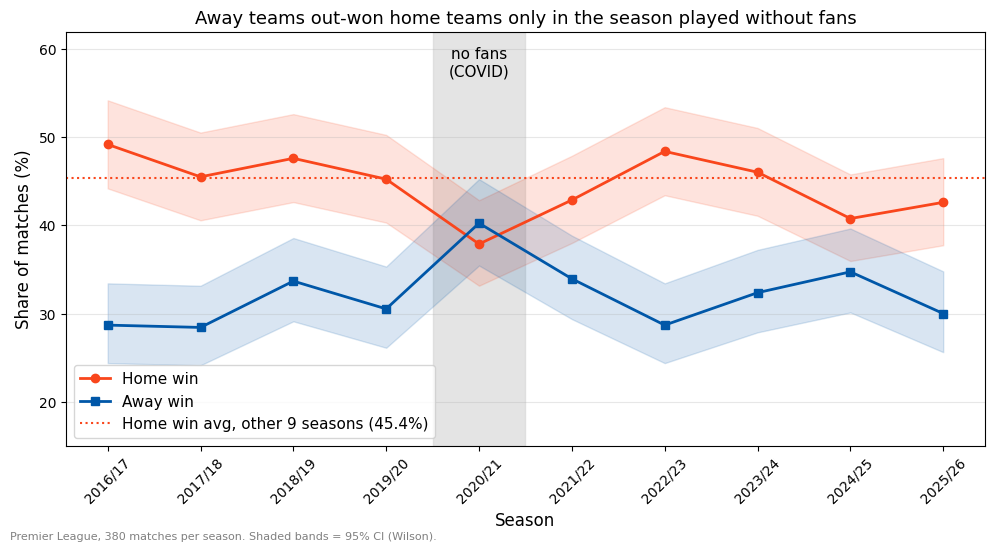

In [6]:
import os
os.makedirs("figures", exist_ok=True)

x = seasons["season"].to_list()
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.axvspan(2019.5, 2020.5, color="lightgrey", alpha=0.6)
ax.text(2020, 57, "no fans\n(COVID)", ha="center", fontsize=11)

for col, label, color, marker in [("home_wins", "Home win", "#f9461c", "o"),
                                  ("away_wins", "Away win", "#0057a8", "s")]:
    lo, hi = proportion_confint(seasons[col].to_numpy(), seasons["matches"].to_numpy(), method="wilson")
    pct = 100 * seasons[col] / seasons["matches"]
    ax.fill_between(x, 100 * lo, 100 * hi, color=color, alpha=0.15)
    ax.plot(x, pct, marker=marker, color=color, linewidth=2, label=label)

ax.axhline(100 * k_rest / n_rest, color="#f9461c", linestyle=":", linewidth=1.5,
           label=f"Home win avg, other 9 seasons ({100*k_rest/n_rest:.1f}%)")

ax.set_xticks(x)
ax.set_xticklabels(seasons["label"].to_list(), rotation=45)
ax.set_ylim(15, 62)
ax.set_xlabel("Season", fontsize=12)
ax.set_ylabel("Share of matches (%)", fontsize=12)
ax.set_title("Away teams out-won home teams only in the season played without fans", fontsize=13)
ax.legend(fontsize=11, loc="lower left")
ax.grid(axis="y", alpha=0.3)
fig.text(0.01, 0.01, "Premier League, 380 matches per season. Shaded bands = 95% CI (Wilson).", fontsize=8, color="grey")
plt.tight_layout()
plt.savefig("figures/finding-3.png", dpi=200)
plt.show()

## Things I tried but left out

First I compared 2020/21 only with 2025/26 (my own season). That one is not significant:

In [7]:
last = seasons.filter(pl.col("season") == 2025)
z2, p2 = proportions_ztest([k_covid, last["home_wins"][0]], [n_covid, last["matches"][0]])
print(f"2020/21 vs 2025/26: z = {z2:.2f}, p = {p2:.3f}")

2020/21 vs 2025/26: z = -1.33, p = 0.183


With only 380 matches on each side the CIs are about +-5 points wide, so one season vs one season can't really show a 4-5 point difference. That's why I used the nine seasons together as the baseline instead.

Other things not in the story:
- the last 92 matches of 2019/20 were also without fans, but they're mixed into Nate's season totals so I can't split them out.
- other leagues in 2020/21 would be a good extra check (is this just a Premier League thing?). We don't have that data in the repo yet, so it's a next step for the final report.

## What this can't tell us

2020/21 wasn't only different because of fans. The schedule was packed, there was almost no preseason, and teams had COVID cases. All of that happened in the same season, so I can only say the drop in home advantage is linked to the season without fans, not that missing fans caused it. Also most matches had no fans but not all (a few rounds in December 2020 and May 2021 had small crowds).